## Part 1

## 1.1  Download data and load that into DF

In [1]:
## Uncomment it and install the required dependencies
# !pip install "gensim==4.3.3" "numpy<2" "scipy<1.14" scikit-learn matplotlib

In [2]:
## imports

import math
from collections import Counter
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from gensim.parsing.preprocessing import STOPWORDS
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [3]:
data_path = "archive/quotes.csv"

df = pd.read_csv(data_path)
df.head()

,quote,author,category
0,"I'm selfish, impatient and a little insecure. ...",Marilyn Monroe,"attributed-no-source, best, life, love, mistak..."
1,You've gotta dance like there's nobody watchin...,William W. Purkey,"dance, heaven, hurt, inspirational, life, love..."
2,You know you're in love when you can't fall as...,Dr. Seuss,"attributed-no-source, dreams, love, reality, s..."
3,A friend is someone who knows all about you an...,Elbert Hubbard,"friend, friendship, knowledge, love"
4,Darkness cannot drive out darkness: only light...,"Martin Luther King Jr., A Testament of Hope: T...","darkness, drive-out, hate, inspirational, ligh..."


In [4]:
df.shape, df.columns

((499709, 3), Index(['quote', 'author', 'category'], dtype='str'))

## 1.2.1, Cleaning Data

In [5]:
df = df.dropna(subset=["quote", "author"])
df.shape

(497956, 3)

In [6]:
print("Before cleaning:", df["author"].nunique())
df["author"] = df["author"].str.split(",").str[0].str.strip()
print("After cleaning:", df["author"].nunique())

Before cleaning: 117296
After cleaning: 77636


In [7]:
df["clean"] = df["quote"].str.lower()
df["clean"] = df["clean"].str.replace("'", "", regex=False)     
df["clean"] = df["clean"].str.replace(r"[^a-z\s]", " ", regex=True)

In [8]:
df["tokens"] = df["clean"].str.split()
df["tokens"] = df["tokens"].apply(lambda words: [w for w in words if w not in STOPWORDS and len(w) > 1])

In [9]:
author_docs = df.groupby("author")["tokens"].agg(lambda lists: [w for t in lists for w in t])
len(author_docs)

77636

## 1.2.2

In [10]:
authors = ["Albert Einstein", "Mark Twain", "Oscar Wilde"]
top_words = {}

for a in authors:
    counts = Counter(w for w in author_docs[a] if len(w) >= 4)
    top_words[a] = counts.most_common(2)

top_words

{'Albert Einstein': [('life', 55), ('human', 37)],
 'Mark Twain': [('good', 64), ('thing', 58)],
 'Oscar Wilde': [('life', 144), ('people', 107)]}

In [11]:
## put all the words into one list and remoce duplication
words = [w for a in authors for w, c in top_words[a]]
words = list(set(words))   # removes duplicates
words

['life', 'people', 'thing', 'human', 'good']

In [12]:
author_docs.head(1)

author
    [les, hommes, construisent, trop, murs, et, pa...
Name: tokens, dtype: object

In [13]:
def tfidf(author_docs, authors, words):
    """
    Compute TF-IDF from scratch.

    TF  = count of word in document / number of words in document
    IDF = log(N / number of documents containing the word)
    """
    # number of documents in the corpus
    N = len(author_docs)

    # document frequency: in how many author documents each word appears
    doc_freq = Counter()
    for doc in author_docs:
        doc_freq.update(set(doc))

    # TF, IDF and TF-IDF for every author-word combination
    rows = []
    for a in authors:
        doc = author_docs[a]
        counts = Counter(doc)
        for w in words:
            tf = counts[w] / len(doc)
            idf = math.log(N / doc_freq[w])
            rows.append({"author": a, "word": w, "tf": tf, "idf": idf, "tfidf": tf * idf})

    return pd.DataFrame(rows)

In [14]:
tfidf_df = tfidf(author_docs, authors, words)
tfidf_df

,author,word,tf,idf,tfidf
0,Albert Einstein,life,0.011331,1.426668,0.016165
1,Albert Einstein,people,0.007417,1.515177,0.011237
2,Albert Einstein,thing,0.004532,2.125032,0.009631
3,Albert Einstein,human,0.007623,2.431146,0.018532
4,Albert Einstein,good,0.002266,1.906732,0.004321
5,Mark Twain,life,0.004634,1.426668,0.006612
6,Mark Twain,people,0.003823,1.515177,0.005793
7,Mark Twain,thing,0.006720,2.125032,0.014280
8,Mark Twain,human,0.002897,2.431146,0.007042
9,Mark Twain,good,0.007415,1.906732,0.014139


In [15]:
tfidf_df.pivot(index="author", columns="word", values="tfidf")

word,good,human,life,people,thing
author,,,,,
Albert Einstein,0.004321,0.018532,0.016165,0.011237,0.009631
Mark Twain,0.014139,0.007042,0.006612,0.005793,0.014280
Oscar Wilde,0.012590,0.002636,0.020246,0.015978,0.018011


## 1.2.3

In [17]:
# 1.2.3 Word2Vec skip-gram models

# each quote becomes a list of words
sentences = df["clean"].str.split().tolist()

# model 1: window = 3, vector size = 50, negative samples = 3
model1 = Word2Vec(sentences, sg=1, window=3, vector_size=50, negative=3, min_count=5)

# model 2: window = 7, vector size = 150, negative samples = 10
model2 = Word2Vec(sentences, sg=1, window=7, vector_size=150, negative=10, min_count=5)

# most similar words to "imagination"
print("Model 1 - most similar to 'imagination':")
print(model1.wv.most_similar(positive=["imagination"]))

print("\nModel 2 - most similar to 'imagination':")
print(model2.wv.most_similar(positive=["imagination"]))

# similarity between "fear" and "knowledge"
print("\nModel 1 - similarity(fear, knowledge):", model1.wv.similarity("fear", "knowledge"))
print("Model 2 - similarity(fear, knowledge):", model2.wv.similarity("fear", "knowledge"))

Model 1 - most similar to 'imagination':
[('intellect', 0.7830418944358826), ('knowledge', 0.779392659664154), ('mind', 0.7765514850616455), ('creativity', 0.7734366655349731), ('craft', 0.7713472843170166), ('subconscious', 0.7588380575180054), ('aspiration', 0.7464643716812134), ('artistry', 0.7405487895011902), ('intuition', 0.737755537033081), ('soul', 0.734197735786438)]

Model 2 - most similar to 'imagination':
[('imaginations', 0.6912034153938293), ('creativity', 0.6688287854194641), ('imaginative', 0.654293417930603), ('mind', 0.6377899646759033), ('figment', 0.6357283592224121), ('fantasy', 0.6307731866836548), ('creative', 0.6291235089302063), ('unguarded', 0.588108479976654), ('figments', 0.5812298059463501), ('overactive', 0.5763402581214905)]

Model 1 - similarity(fear, knowledge): 0.49082077
Model 2 - similarity(fear, knowledge): 0.37713036


## 1.2.4

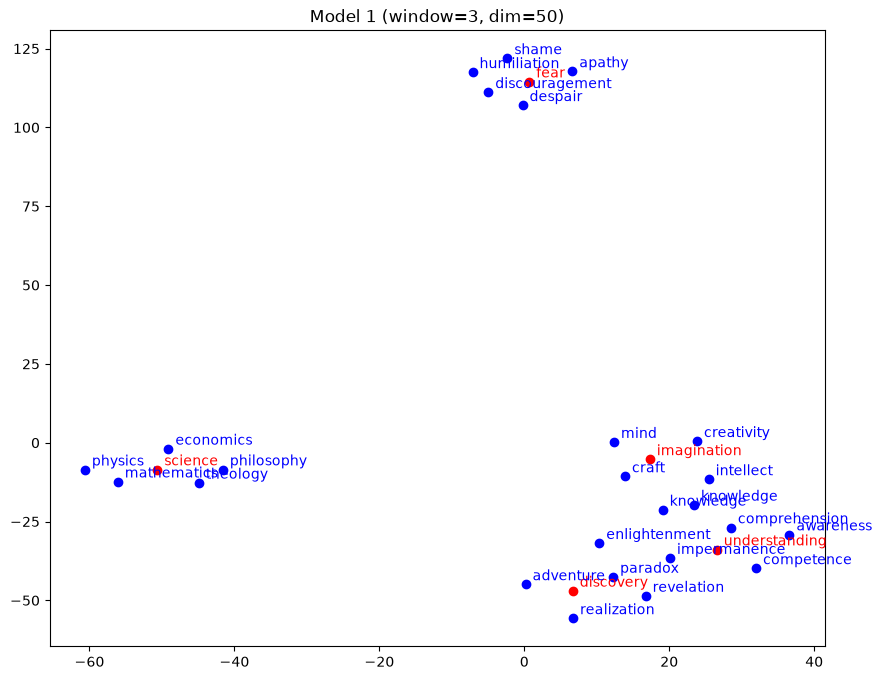

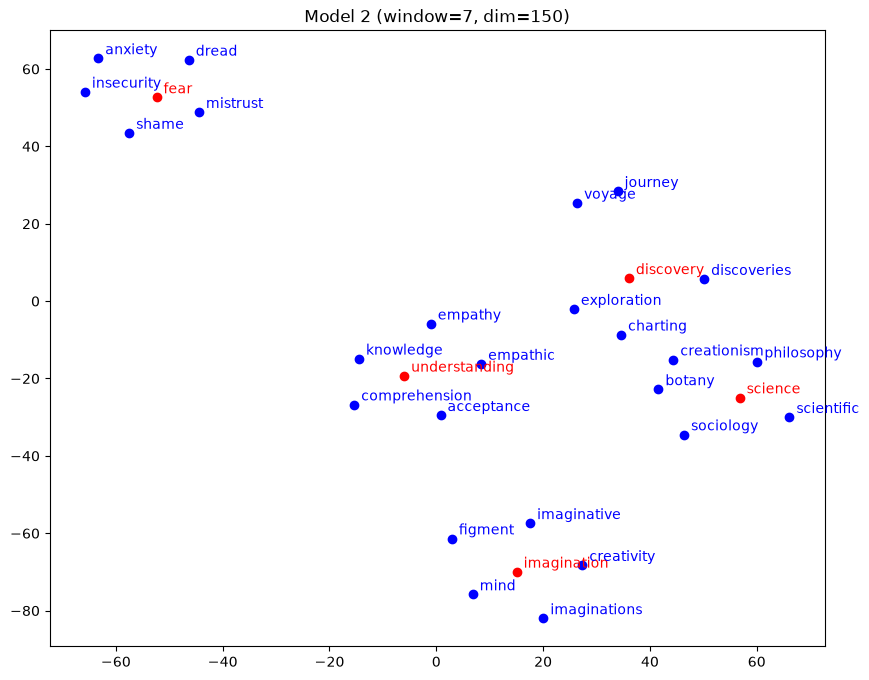

In [18]:
key_words = ["imagination", "fear", "understanding", "discovery", "science"]

def plot_tsne(model, title):
    words = []
    for w in key_words:
        words.append(w)
        for similar_words, score in model.wv.most_similar(w, topn=5):
            words.append(similar_words)
    
    vectors = np.array([model.wv[w] for w in words])
    points = TSNE(n_components=2, perplexity=5, random_state=42).fit_transform(vectors)
    
    plt.figure(figsize=(10, 8))
    for i, w in enumerate(words):
        color = "red" if w in key_words else "blue"
        plt.scatter(points[i, 0], points[i, 1], color=color)
        plt.annotate(w, (points[i, 0], points[i, 1]), color=color,
                     xytext=(5, 3), textcoords="offset points")   
    plt.title(title)
    plt.show()

plot_tsne(model1, "Model 1 (window=3, dim=50)")
plot_tsne(model2, "Model 2 (window=7, dim=150)")

## 1.2.5

In [19]:
# 1.2.5 Compare embeddings of the key words

key_words = ["imagination", "fear", "understanding", "discovery", "science"]

# cosine similarity between every pair of key words, for each model
sim1 = pd.DataFrame([[model1.wv.similarity(a, b) for b in key_words] for a in key_words],
                    index=key_words, columns=key_words)
sim2 = pd.DataFrame([[model2.wv.similarity(a, b) for b in key_words] for a in key_words],
                    index=key_words, columns=key_words)

print("Model 1 (window=3, dim=50):")
print(sim1.round(3))
print("\nModel 2 (window=7, dim=150):")
print(sim2.round(3))

# how many of the top 10 neighbours are the same in both models
print("\nShared top-10 neighbours:")
for w in key_words:
    n1 = [x for x, s in model1.wv.most_similar(w, topn=10)]
    n2 = [x for x, s in model2.wv.most_similar(w, topn=10)]
    shared = set(n1) & set(n2)
    print(w, "->", len(shared), shared)

Model 1 (window=3, dim=50):
               imagination   fear  understanding  discovery  science
imagination          1.000  0.478          0.661      0.589    0.578
fear                 0.478  1.000          0.510      0.472    0.268
understanding        0.661  0.510          1.000      0.659    0.613
discovery            0.589  0.472          0.659      1.000    0.493
science              0.578  0.268          0.613      0.493    1.000

Model 2 (window=7, dim=150):
               imagination   fear  understanding  discovery  science
imagination          1.000  0.432          0.444      0.371    0.448
fear                 0.432  1.000          0.372      0.303    0.226
understanding        0.444  0.372          1.000      0.467    0.463
discovery            0.371  0.303          0.467      1.000    0.515
science              0.448  0.226          0.463      0.515    1.000

Shared top-10 neighbours:
imagination -> 2 {'mind', 'creativity'}
fear -> 2 {'shame', 'discouragement'}
understan

In [ ]:
n1, n2

(['philosophy',
  'mathematics',
  'theology',
  'economics',
  'physics',
  'metaphysics',
  'literature',
  'scientific',
  'journalism',
  'astronomy'],
 ['philosophy',
  'scientific',
  'physics',
  'economics',
  'mathematics',
  'creationism',
  'naturalism',
  'astronomy',
  'newtonian',
  'botany'])

Comparing the two models shows that both the context window and the vector size change how the words relate to each other.

Context window. The bigger window changed which words were closest to each other, not just how close they were. In Model 1, imagination was clearly closest to understanding (0.661), but in Model 2 it was about equally close to science (0.448), understanding (0.444) and fear (0.432). With a window of 7 the model sees most of the quote, so words get tied to what they show up alongside, not just to words used the same way. The one pair that actually got closer was discovery and science (0.493 → 0.515), which became the most similar pair in Model 2 and fits the idea that a bigger window groups words by topic. You can see this in the neighbours too, since Model 2 added words like figment and overactive that usually appear right around “imagination”.

Dimensionality. Every similarity dropped in Model 2, and the scores got more bunched together, for example, fear/knowledge went from 0.491 to 0.377. My guess is that 150 dimensions gives the model more room to spread words apart, while 50 dimensions squeezes abstract words together. Some things stayed the same, like fear being the least similar to science in both models (0.268 and 0.226). The two models shared anywhere from 0 (discovery) to 6 (science) of their top 10 neighbours, and since I changed the window, dimensions and negative samples all at once, I can’t say exactly which setting caused which difference.

# Part 2

In [20]:
## imports
import numpy as np
import pandas as pd
import gensim.downloader as downloader
from gensim.models import KeyedVectors


In [21]:
## Load glove
glove = downloader.load("glove-wiki-gigaword-300")
len(glove.key_to_index)

400000

In [22]:
## load word to vec
word2vec = downloader.load("word2vec-google-news-300", return_path=True)

In [23]:
w2v = KeyedVectors.load_word2vec_format(word2vec, binary=True, limit=400000)
len(w2v.key_to_index)


400000

## 2.1

In [24]:
# read the analogy file and keep only the 8 groups we need
groups = ["capital-world", "currency", "city-in-state", "family",
          "gram1-adjective-to-adverb", "gram2-opposite", "gram3-comparative",
          "gram6-nationality-adjective"]

questions = {}
current = None
for line in open("word-test.v1.txt"):
    line = line.strip()
    if line.startswith(":"):
        current = line[1:].strip()
        if current in groups:
            questions[current] = []
    elif current in groups and line:
        questions[current].append(line.split())

for g in questions:
    print(g, len(questions[g]))

capital-world 4524
currency 866
city-in-state 2467
family 506
gram1-adjective-to-adverb 992
gram2-opposite 812
gram3-comparative 1332
gram6-nationality-adjective 1599


In [25]:
## analogy fucntion
def predict_analogy(model, normalized_vectors, a, b, c):
    # d = argmax cos(v_d, v_b - v_a + v_c), not counting a, b, c
    idx = model.key_to_index
    target = normalized_vectors[idx[b]] - normalized_vectors[idx[a]] + normalized_vectors[idx[c]]

    scores = normalized_vectors @ target          # cosine similarity with every word
    scores[[idx[a], idx[b], idx[c]]] = -np.inf                  # don't allow a, b, c as answers

    return model.index_to_key[np.argmax(scores)]

print(predict_analogy(glove, glove.get_normed_vectors(), "bangkok", "thailand", "cairo"))

egypt


In [26]:
def accuracy(model, qs, lowercase):
    normalized_vectors = model.get_normed_vectors()
    correct = 0
    for q in qs:
        a, b, c, d = [w.lower() for w in q] if lowercase else q
        # only count it as correct if all words exist and the prediction matches d
        if all(w in model for w in (a, b, c, d)) and predict_analogy(model, normalized_vectors, a, b, c) == d:
            correct += 1
    return correct / len(qs)

results = pd.DataFrame({
    "word2vec": {g: accuracy(w2v, questions[g], lowercase=False) for g in groups},
    "GloVe":    {g: accuracy(glove, questions[g], lowercase=True) for g in groups},
})
results.loc["average"] = results.mean()
results.round(3)

,word2vec,GloVe
capital-world,0.791,0.960
currency,0.320,0.158
city-in-state,0.720,0.593
family,0.852,0.881
gram1-adjective-to-adverb,0.293,0.226
gram2-opposite,0.431,0.273
gram3-comparative,0.911,0.881
gram6-nationality-adjective,0.901,0.926
average,0.652,0.612


## Report
Embeddings used. I compared two sets of pretrained embeddings that both have 300 dimensions. The first was word2vec trained on Google News (about 100 billion words, case-sensitive), and I only kept its 400,000 most common words so it would fit in memory. The second was GloVe trained on Wikipedia and Gigaword (about 6 billion words, all lowercase, 400,000 words). For GloVe I lowercased the questions, and if any word in a question was missing from the vocabulary I just counted it as wrong.

Results. Both models did really well on the simpler patterns like family words, comparatives and nationalities, getting over 85% right. GloVe was much better at capital cities (96% vs 79%), which I think comes from Wikipedia having so much geography in it. word2vec did better on currencies and US cities with their states, which makes sense for news articles, where you constantly see things like “Houston, Texas”. On a plain average across the groups word2vec scored a bit higher (65% vs 61%), but if you weight by the number of questions GloVe actually comes out slightly ahead, since capital-world is by far the biggest group.

Hardest groups. Both models had the most trouble with adjective-to-adverb and opposites, scoring between 23% and 43%. For opposites, a lot of the answers are rare words like “uncompetitive”, and opposite words tend to end up close together in the embedding space anyway. For adverbs, the model often just picked another form of the adjective instead of the actual adverb.

# 2.2 Code

In [27]:
# Antonyms: checking if opposite words show up as most similar

# increase -> antonym: decrease
print("word2vec:", w2v.most_similar("increase", topn=10))
print("GloVe:", glove.most_similar("increase", topn=10))

# enter -> antonym: exit
print("\nword2vec:", w2v.most_similar("enter", topn=10))
print("GloVe:", glove.most_similar("enter", topn=10))

# open -> antonym: close
print("\nword2vec:", w2v.most_similar("open", topn=10))
print("GloVe:", glove.most_similar("open", topn=10))

word2vec: [('decrease', 0.8370317816734314), ('increases', 0.7709377408027649), ('increased', 0.7578042149543762), ('reduction', 0.6908220052719116), ('increasing', 0.6871615648269653), ('decreases', 0.6816173791885376), ('rise', 0.6352646946907043), ('decreasing', 0.6218625903129578), ('decline', 0.6128641366958618), ('uptick', 0.5923734903335571)]
GloVe: [('increased', 0.860288143157959), ('increases', 0.8352779746055603), ('decrease', 0.8139814734458923), ('increasing', 0.7714847922325134), ('reduce', 0.70950847864151), ('boost', 0.6809046864509583), ('rise', 0.6780449151992798), ('reduction', 0.666925311088562), ('reduced', 0.654766857624054), ('significantly', 0.6326099634170532)]

word2vec: [('entering', 0.7399863600730896), ('entered', 0.6956064105033875), ('reenter', 0.6487391591072083), ('enters', 0.5622495412826538), ('entry', 0.5517960786819458), ('Entering', 0.4845679700374603), ('participate', 0.4820388853549957), ('leave', 0.4764121174812317), ('join', 0.4726879894733429)

# 2.2 Discussion
Results. Both embeddings put antonyms really close together. For “increase”, word2vec actually ranked “decrease” as the most similar word (0.837), even higher than “increases” or “increased”, and GloVe had it third. “Open” was similar, with “closed” in the top 5 for both models and “close” also showing up in word2vec’s list. “Enter” was the one exception, since “exit” didn’t show up at all, and I think that’s because “exit” is used as a noun a lot (exit polls, exit signs), so it doesn’t really appear in the same sentences as “enter”.

Why this happens. These embeddings learn a word’s meaning from the words around it, and opposites usually get used in almost the same way. You’d see “prices will increase by 5%” and “prices will decrease by 5%”, or “the store opens at 9” and “the store closes at 9”, so the model ends up learning nearly the same vector for both. They also tend to show up right next to each other, like “increase or decrease” or “open and close”, which pulls them even closer. Basically, the model only learns which words are related, not whether they mean the same thing or the opposite.

# 2.3 bonus - my own analogy tests

In [28]:
# type 1: countries in conflict
candidate_1 = [["India", "Pakistan", "Russia", "Ukraine"],
               ["Greece", "Turkey", "Israel", "Palestine"],
               ["China", "Taiwan", "Armenia", "Azerbaijan"]]
# type 2: sport -> league
candidate_2 = [["basketball", "NBA", "hockey", "NHL"],
               ["hockey", "NHL", "baseball", "MLB"],
               ["baseball", "MLB", "football", "NFL"]]


for name, model, lower in [("word2vec", w2v, False), ("GloVe", glove, True)]:
    normed = model.get_normed_vectors()
    print("\n" + name)
    for q in candidate_1 + candidate_2:
        a, b, c, d = [w.lower() for w in q] if lower else q
        if all(w in model for w in (a, b, c, d)):
            print(a, b, c, "->", predict_analogy(model, normed, a, b, c), "| answer:", d)
        else:
            print(a, b, c, "-> missing word")


word2vec
India Pakistan Russia -> Azerbaijan | answer: Ukraine
Greece Turkey Israel -> Israeli | answer: Palestine
China Taiwan Armenia -> Armenian | answer: Azerbaijan
basketball NBA hockey -> NHL | answer: NHL
hockey NHL baseball -> MLB | answer: MLB
baseball MLB football -> NFL | answer: NFL

GloVe
india pakistan russia -> ukraine | answer: ukraine
greece turkey israel -> israeli | answer: palestine
china taiwan armenia -> nagorno-karabakh | answer: azerbaijan
basketball nba hockey -> nhl | answer: nhl
hockey nhl baseball -> mlb | answer: mlb
baseball mlb football -> nfl | answer: nfl


## 2.3 - Discussion

I made two new analogy types: countries in conflict (India : Pakistan :: Russia : Ukraine, Greece : Turkey :: Israel : Palestine, China : Taiwan :: Armenia : Azerbaijan) and sport to league (basketball : NBA :: hockey : NHL, hockey : NHL :: baseball : MLB, baseball : MLB :: football : NFL). Both models got all three sports questions right, which makes sense because leagues are mentioned in a really consistent way in news and Wikipedia. Overall word2vec got 3 out of 6 and GloVe got 4 out of 6.

The conflict questions were much harder. GloVe got Russia → Ukraine, while word2vec picked Azerbaijan, another former Soviet country. For Armenia, GloVe picked Nagorno-Karabakh, the region Armenia and Azerbaijan are fighting over, so it “knew” the conflict but gave the place instead of the country. For Israel and Armenia the models often just returned “Israeli” or “Armenian”, which shows that when they can’t find the relationship, they fall back to a word close to the third word.